In [104]:
print("Butterfly Species Classifier")

Butterfly Species Classifier


In [105]:
import pandas as pd
import sklearn

print("Panda ver: ", pd.__version__)
print("Skikit learn ver: ", sklearn.__version__)

Panda ver:  2.2.3
Skikit learn ver:  1.6.1


In [106]:
url = "https://raw.githubusercontent.com/RiesLabGU/LepTraits/main/consensus/consensus.csv"
df = pd.read_csv(url)
print(df.shape)
print(df.head())


(12448, 43)
        Family    Genus                 Species         verbatimSpecies  \
0  Hesperiidae  Abantis  Abantis arctomarginata  Abantis arctomarginata   
1  Hesperiidae  Abantis        Abantis bamptoni        Abantis bamptoni   
2  Hesperiidae  Abantis         Abantis bergeri         Abantis bergeri   
3  Hesperiidae  Abantis         Abantis bicolor         Abantis bicolor   
4  Hesperiidae  Abantis       Abantis bismarcki       Abantis bismarcki   

   WS_L_Fem  WS_U_Fem  WS_L_Mal  WS_U_Mal  WS_L  WS_U  ...  \
0       NaN       NaN       NaN       NaN   NaN   NaN  ...   
1       NaN       NaN       NaN       NaN   NaN   NaN  ...   
2       NaN       NaN       NaN       NaN   NaN   NaN  ...   
3       NaN       NaN       NaN       NaN   NaN   NaN  ...   
4       NaN       NaN       NaN       NaN   NaN   2.0  ...   

               EdgeAffinity                      MoistureAffinity  \
0                       NaN                                   NaN   
1                       Na

In [107]:
print(df.columns.tolist())

['Family', 'Genus', 'Species', 'verbatimSpecies', 'WS_L_Fem', 'WS_U_Fem', 'WS_L_Mal', 'WS_U_Mal', 'WS_L', 'WS_U', 'FW_L_Fem', 'FW_U_Fem', 'FW_L_Mal', 'FW_U_Mal', 'FW_L', 'FW_U', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'FlightDuration', 'DiapauseStage', 'Voltinism', 'OvipositionStyle', 'CanopyAffinity', 'EdgeAffinity', 'MoistureAffinity', 'DisturbanceAffinity', 'NumberOfHostplantFamilies', 'SoleHostplantFamily', 'PrimaryHostplantFamily', 'SecondaryHostplantFamily', 'EqualHostplantFamily', 'NumberOfHostplantAccounts', 'DateCreated']


In [108]:
print("Null values: ", df.isnull().sum())
print("Unique: ",df["Species"].nunique())
print("Most common species:",df["Species"].value_counts().head(10))

#from output, it is clear that there is a lot of missing data for present species, so "Species" classification may not be accurate, hence we will test family.

Null values:  Family                           0
Genus                            0
Species                          0
verbatimSpecies                  0
WS_L_Fem                     11407
WS_U_Fem                     10250
WS_L_Mal                     11315
WS_U_Mal                      9951
WS_L                          8854
WS_U                          5635
FW_L_Fem                     12448
FW_U_Fem                     12448
FW_L_Mal                     12448
FW_U_Mal                     12448
FW_L                         12093
FW_U                         11555
Jan                           5930
Feb                           5930
Mar                           5930
Apr                           5930
May                           5930
Jun                           5931
Jul                           5930
Aug                           5930
Sep                           5930
Oct                           5930
Nov                           5930
Dec                           5931
Flight

In [109]:
print("Unique families:", df["Family"].nunique())

print("\nRecords per family:")
print(df["Family"].value_counts().head(15))

Unique families: 6

Records per family:
Family
Nymphalidae     3978
Lycaenidae      3395
Hesperiidae     2754
Riodinidae      1056
Pieridae         733
Papilionidae     532
Name: count, dtype: int64


In [110]:
features = ["WS_L", "WS_U", "FW_L", "FW_U"]

print(df[features].notnull().sum())

WS_L    3594
WS_U    6813
FW_L     355
FW_U     893
dtype: int64


In [111]:
features = ["WS_L", "WS_U"]

print("Rows with both measurements:")
print(df[features].notnull().all(axis=1).sum())

print("\nRows missing at least one measurement:")
print(df[features].isnull().any(axis=1).sum())

Rows with both measurements:
3594

Rows missing at least one measurement:
8854


In [112]:
plant_features = [
    "NumberOfHostplantFamilies",
    "SoleHostplantFamily",
    "PrimaryHostplantFamily",
    "SecondaryHostplantFamily",
    "EqualHostplantFamily"
]

print(df[plant_features].head(10))

print("\nUnique values in number of host-plant families:")
print(df["NumberOfHostplantFamilies"].value_counts().head(10))

   NumberOfHostplantFamilies SoleHostplantFamily PrimaryHostplantFamily  \
0                        1.0      Phyllanthaceae                    NaN   
1                        1.0      Phyllanthaceae                    NaN   
2                        NaN                 NaN                    NaN   
3                        1.0           Malvaceae                    NaN   
4                        1.0      Phyllanthaceae                    NaN   
5                        NaN                 NaN                    NaN   
6                        1.0            Fabaceae                    NaN   
7                        2.0                 NaN              Malvaceae   
8                        NaN                 NaN                    NaN   
9                        NaN                 NaN                    NaN   

  SecondaryHostplantFamily EqualHostplantFamily  
0                      NaN                  NaN  
1                      NaN                  NaN  
2                      N

In [113]:

features = [
    "WS_U",
    "NumberOfHostplantFamilies",
    "PrimaryHostplantFamily",
    "SecondaryHostplantFamily"
]

X = df[features]
y = df["Family"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())


Feature shape: (12448, 4)
Target shape: (12448,)

Target classes:
Family
Nymphalidae     3978
Lycaenidae      3395
Hesperiidae     2754
Riodinidae      1056
Pieridae         733
Papilionidae     532
Name: count, dtype: int64


In [114]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 9958
Testing records: 2490


In [115]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["WS_U", "NumberOfHostplantFamilies"]

categorical_features = [
    "PrimaryHostplantFamily",
    "SecondaryHostplantFamily"
]

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Preprocessing setup complete!")


Preprocessing setup complete!


In [116]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier


dt_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])


knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])


dt_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

print("Both models trained successfully!")


Both models trained successfully!


In [117]:

from sklearn.metrics import accuracy_score


dt_predictions = dt_model.predict(X_test)
knn_predictions = knn_model.predict(X_test)


dt_accuracy = accuracy_score(y_test, dt_predictions)
knn_accuracy = accuracy_score(y_test, knn_predictions)

print(f"Decision Tree Accuracy: {dt_accuracy:.4f} ({dt_accuracy * 100:.2f}%)")
print(f"KNN Accuracy: {knn_accuracy:.4f} ({knn_accuracy * 100:.2f}%)")


Decision Tree Accuracy: 0.3972 (39.72%)
KNN Accuracy: 0.4201 (42.01%)


In [118]:

from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

dt_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

dt_params = {
    "classifier__max_depth": [5, 10, 20, None],
    "classifier__min_samples_leaf": [1, 5, 10, 20],
    "classifier__criterion": ["gini", "entropy"]
}

dt_search = GridSearchCV(
    dt_pipeline,
    dt_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

dt_search.fit(X_train, y_train)

print("Best parameters:", dt_search.best_params_)
print("Best CV accuracy:",
      round(dt_search.best_score_ * 100, 2), "%")


Best parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1}
Best CV accuracy: 40.51 %


In [119]:

from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

knn_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier())
])

knn_params = {
    "classifier__n_neighbors": [3, 5, 7, 11, 15, 21],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2]
}

knn_search = GridSearchCV(
    knn_pipeline,
    knn_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

print("Best parameters:", knn_search.best_params_)
print("Best CV accuracy:",
      round(knn_search.best_score_ * 100, 2), "%")


Best parameters: {'classifier__n_neighbors': 21, 'classifier__p': 1, 'classifier__weights': 'distance'}
Best CV accuracy: 44.79 %


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [       nan 0.39164917 0.37748316 0.38099757        nan 0.39395835
 0.38009209 0.38491192        nan 0.39938171 0.41444558 0.41715627
        nan 0.40801846 0.43613132 0.4410513         nan 0.41474724
 0.43562875 0.44115049        nan 0.44788158 0.4132401  0.41785858]
  warnings.warn(


In [120]:

knn_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier(algorithm="brute"))
])

knn_params = {
    "classifier__n_neighbors": [5, 7, 11, 15, 21],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2]
}

knn_search = GridSearchCV(
    knn_pipeline,
    knn_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

print("Best parameters:", knn_search.best_params_)
print("Best CV accuracy:",
      round(knn_search.best_score_ * 100, 2), "%")


Best parameters: {'classifier__n_neighbors': 21, 'classifier__p': 1, 'classifier__weights': 'distance'}
Best CV accuracy: 44.79 %


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [       nan 0.39395835 0.38009209 0.38491192        nan 0.39938171
 0.41444558 0.41715627        nan 0.40801846 0.43613132 0.4410513
        nan 0.41474724 0.43562875 0.44115049        nan 0.44788158
 0.4132401  0.41785858]
  warnings.warn(


In [121]:

from sklearn.metrics import accuracy_score
import pandas as pd

models = {
    "Decision Tree (tuned)": dt_search.best_estimator_,
    "KNN (tuned)": knn_search.best_estimator_
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Test accuracy (%)": round(accuracy * 100, 2)
    })

print(pd.DataFrame(results).to_string(index=False))


                Model  Test accuracy (%)
Decision Tree (tuned)              39.72
          KNN (tuned)              44.06


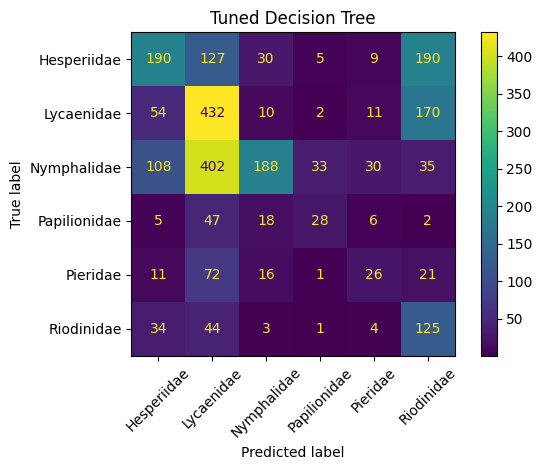

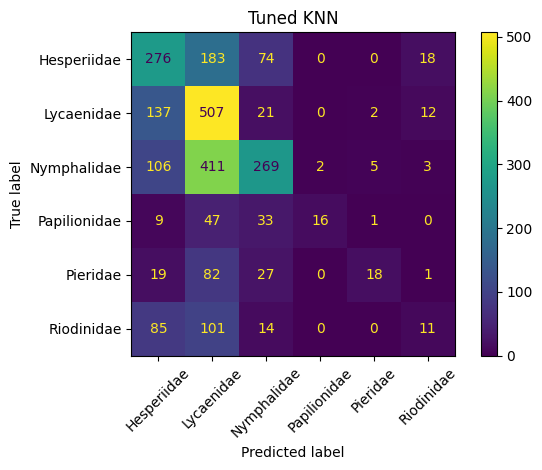

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Hesperiidae       0.47      0.34      0.40       551
  Lycaenidae       0.38      0.64      0.48       679
 Nymphalidae       0.71      0.24      0.35       796
Papilionidae       0.40      0.26      0.32       106
    Pieridae       0.30      0.18      0.22       147
  Riodinidae       0.23      0.59      0.33       211

    accuracy                           0.40      2490
   macro avg       0.42      0.38      0.35      2490
weighted avg       0.49      0.40      0.39      2490

KNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Hesperiidae       0.44      0.50      0.47       551
  Lycaenidae       0.38      0.75      0.50       679
 Nymphalidae       0.61      0.34      0.44       796
Papilionidae       0.89      0.15      0.26       106
    Pieridae       0.69      0.12      0.21       147
  Riodinidae       0.24      0.05      0.09       211

    accuracy   

In [122]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best_dt = dt_search.best_estimator_
best_knn = knn_search.best_estimator_

dt_predictions = best_dt.predict(X_test)
knn_predictions = best_knn.predict(X_test)

# Decision Tree
ConfusionMatrixDisplay.from_predictions(
    y_test, dt_predictions, xticks_rotation=45
)
plt.title("Tuned Decision Tree")
plt.tight_layout()
plt.show()

# KNN
ConfusionMatrixDisplay.from_predictions(
    y_test, knn_predictions, xticks_rotation=45
)
plt.title("Tuned KNN")
plt.tight_layout()
plt.show()

print("DECISION TREE CLASSIFICATION REPORT")
print(classification_report(y_test, dt_predictions, zero_division=0))

print("KNN CLASSIFICATION REPORT")
print(classification_report(y_test, knn_predictions, zero_division=0))
